### Flat Magnitude Reconstruction
Flat magnitude reconstruction consists of manipulating the magnitude spectrum of sound to make the amplitude/magnitude of all sinusoids in the signal equal (MIR book).

FMR causes all of the frequency information to dissapear, causing a noisy texture (MIR book).
The phase spectrum is preserved, the rythmic characteristics and time information is mostly preserved (MIR book). It has also been found that the phase spectrum primarily contributes to speech intelligibility, meaning that lyrics can still be understood when flat magnitude reconstruction is applied to audio (Paliwal & Alsteris, 2005).


### References
*  Paliwal, K. K., & Alsteris, L. D. (2005). On the usefulness of STFT phase spectrum in human listening tests. *Speech Communication*, 45(2), 153–170. https://doi.org/10.1016/j.specom.2004.08.001
*  MIR Book : DFT Part 6: https://github.com/gtzan/mir_book/blob/master/ch1_sinusoidworld/Explaining_the_DFT_a_music_perspective_part6.ipynb



In [ ]:
import IPython.display as ipd
import numpy as np
import scipy.fft as fft
from scipy.io import wavfile
from scipy.io.wavfile import write
import matplotlib.pyplot as plt

# use this filename when working locally
#filename = '/content/tomsdiner_mono.wav'
# use this filename when working within github
filename = '../../data/tomsdiner_mono.wav'
srate, tomsdiner = wavfile.read(filename)
ipd.Audio(tomsdiner, rate=srate)

In [24]:
def save_audio_to_wav(filename, audio, srate=44100):
  """Saves an audio array as a wav file"""
  audio = audio / np.max(np.abs(audio))
  write(filename, srate, audio.astype(np.float32))

# slightly different from MIR book: takes amplitude as input instead of setting
# all amplitudes to 1
def flat_magnitude_reconstruct(signal: np.ndarray, amplitude: float) -> np.ndarray:
  '''
  Flat magnitude reconstruction on a signal.

  This function takes the input signal, converts the signal from time domain to
  frequency domain using the FFT, then sets all amplitudes to the same magnitude
  before converting the signal back to the time domain using the IFFT. The phase
  spectrum remains the same.

  Args:
    signal (np.ndarray): the samples of the signal
    amplitude (float): the amplitude, a float between 0.0 and 1.0

  Returns:
    np.ndarray: the reconstructed signal

  Raises:
    ValueError: if the amplitude is not between 0.0 and 1.0
  '''
  if (amplitude < 0.0) or (amplitude > 1.0):
    raise ValueError('Amplitude must be between 0.0 and 1.0')

  # Convert the time-domain audio signal to a frequency-domain array of complex coefficients using fft
  # We use rfft because the audio samples are real-valued, so rfft returns only non-negative frequencies and avoids redundant info
  complex_spectrum = fft.rfft(signal)

  # Set all magnitudes to the same given amplitude
  magnitude_spectrum = np.full(len(complex_spectrum), amplitude)

  # Phase spectrum remains unchanged
  phase_spectrum = np.angle(complex_spectrum)

  # reconstruct the signal in frequency domain with the new magnitude spectrum
  reconstructed_complex_spectrum = magnitude_spectrum *(np.cos(phase_spectrum) + 1j*np.sin(phase_spectrum))
  reconstructed_signal = fft.irfft(reconstructed_complex_spectrum)

  return reconstructed_signal


flat_toms_diner = flat_magnitude_reconstruct(tomsdiner, 1.0)
ipd.Audio(flat_toms_diner, rate=srate, normalize=False)

# save audio
save_audio_to_wav('audios/flat_magnitude_reconstructed_toms_diner.wav', flat_toms_diner, srate)


In [8]:
half_flat_toms_diner = flat_magnitude_reconstruct(tomsdiner, 0.5)
ipd.Audio(half_flat_toms_diner, rate=srate, normalize=False)

# save audio
save_audio_to_wav('audios/half_flat_magnitude_reconstructed_toms_diner.wav', half_flat_toms_diner, srate)

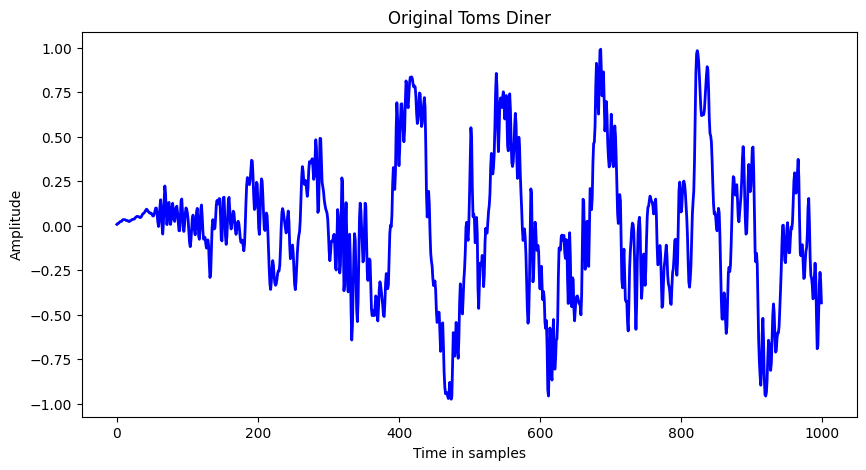

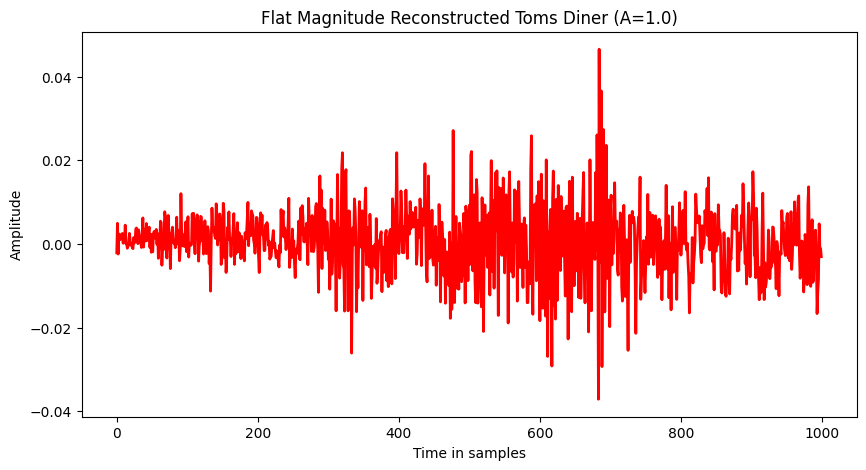

In [27]:
fig = plt.figure(figsize=(10,5))
plt.xlabel("Time in samples")
plt.ylabel("Amplitude")
plt.title("Original Toms Diner")
tomsdiner_normalized = tomsdiner.astype(np.float64) / 32768.0
plt.plot(tomsdiner_normalized[0:1000], lw=2, color='blue')
plt.savefig('plots/original_toms_diner_normalized.png')
plt.show()


# Notice the amplitude still fluctuates a bit. This is because we were setting the
# magnitudes of the frequency components to the same value, not the amplitudes of
# the time domain samples. Therefore every frequency component now has a magnitude
# of 1.0, but each component still has its original phase

# When we reconstructed the signal using the ifft, all of the frequency components
# were added together, and constructive interference (aligned sinusoids) and
# destructive interference (opposing sinusoids), creating large and small peaks.

# The maximum amplitude of the reconstructed wave is significantly decreased
# because we have reduced the stronger frequency components and increased the
# weaker frequncy components all to the same amplitudes, now their combined peaks
# are generally smaller.
fig = plt.figure(figsize=(10,5))
plt.xlabel("Time in samples")
plt.ylabel("Amplitude")
plt.title("Flat Magnitude Reconstructed Toms Diner (A=1.0)")
plt.plot(flat_toms_diner[0:1000], lw=2, color='red')
plt.savefig('plots/flat_magnitude_reconstructed_toms_diner.png')
plt.show()

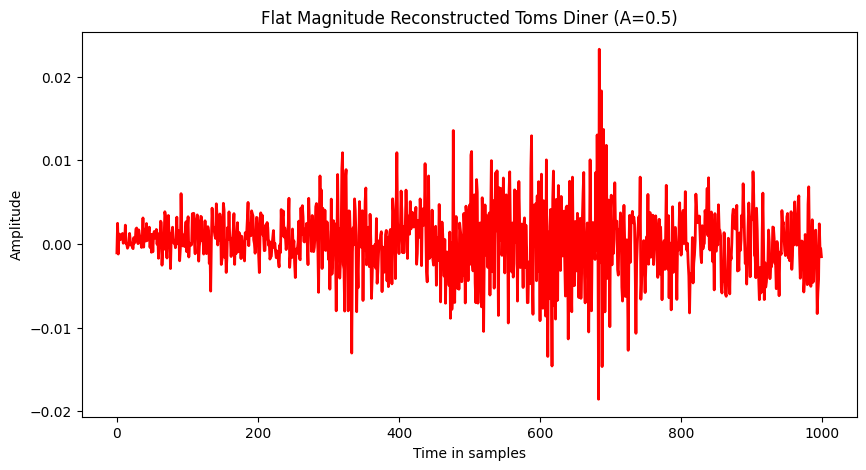

In [19]:
fig = plt.figure(figsize=(10,5))
plt.xlabel("Time in samples")
plt.ylabel("Amplitude")
plt.title("Flat Magnitude Reconstructed Toms Diner (A=0.5)")
plt.plot(half_flat_toms_diner[0:1000], lw=2, color='red')
plt.show()

In [16]:
# lets use flat magnitude reconstruction to "fade out" the song! Normally we would
# use amplitude envelopes for this, but this could produce an interesting effect

num_segments = len(tomsdiner) // 10000
segments = np.array_split(tomsdiner, num_segments)

faded_segments = []

for i, segment in enumerate(segments):
    if i < num_segments / 2:
        amplitude = 1.0
    else:
        amplitude = 1.0 - ((i - num_segments / 2) / (num_segments / 2 - 1))

    faded = flat_magnitude_reconstruct(segment, amplitude)
    faded_segments.append(faded)

fade_out = np.concatenate(faded_segments)

# sounds insane, lots of speckles and cracks, but interesting I guess?
ipd.Audio(fade_out, rate=srate, normalize=False)

# save audio
save_audio_to_wav('audios/fade_out_flat_magnitude_reconstructed_toms_diner.wav', fade_out, srate)
